In [1]:
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

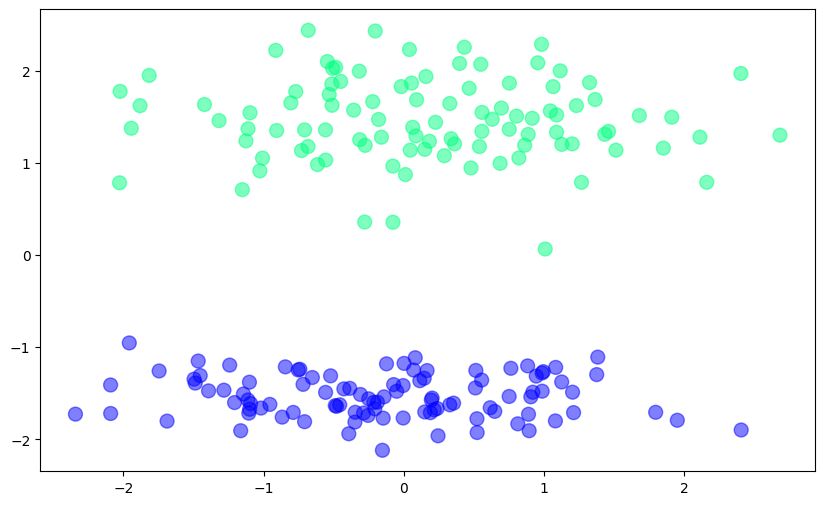

In [2]:
x,y = make_classification(n_samples=200,n_features=2,n_informative=1,n_redundant=0,n_classes=2,n_clusters_per_class=1,class_sep=1.5,random_state=41)
plt.figure(figsize=(10,6))
plt.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100,alpha=0.5)

In [3]:
x

array([[ 0.48029527,  0.94384393],
       [ 0.54063327,  1.17559784],
       [ 1.20527815, -1.4872231 ],
       [-0.3479525 , -1.81112196],
       [-1.68849883, -1.80077934],
       [ 0.52440461, -1.92447768],
       [ 0.15883969,  1.93482221],
       [-0.75240421, -1.24601437],
       [ 1.20302764,  1.20467672],
       [-0.55791394,  1.35621752],
       [-0.61496914,  0.98084989],
       [-1.11131134, -1.57190686],
       [-1.4662421 , -1.14935697],
       [ 0.65006845, -1.69502525],
       [ 1.09103671,  1.33042169],
       [-0.51261084,  1.85278791],
       [-1.15156279,  0.70786344],
       [ 0.51502711, -1.25114578],
       [-0.30856354, -1.51194707],
       [ 0.04134689,  2.22785903],
       [-0.91279942,  2.21830555],
       [ 0.29020614,  1.07619076],
       [ 0.22748581,  1.43862837],
       [ 0.61753579, -1.6554344 ],
       [-1.00736935,  1.05020996],
       [-1.95818506, -0.95317362],
       [-1.49577787, -1.34596737],
       [ 0.81451095, -1.83007464],
       [-0.2493629 ,

In [4]:
y

array([1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       0, 0])

In [5]:
def step(z):
  return 1 if z > 0 else 0

In [6]:
def perceptron(x,y):
  x = np.insert(x,0,1,axis=1)
  weights = np.ones(x.shape[1])
  lr = 0.1

  for i in range(1000):
    j = np.random.randint(0,200)
    y_hat = step(np.dot(x[j],weights))
    weights = weights + lr*(y[j] - y_hat)*x[j]

  return weights[0],weights[1:]

In [7]:
intercept_,coef_ = perceptron(x,y)
print(intercept_)
print(coef_)

0.6000000000000001
[0.56371224 1.49299323]


In [8]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

print(m)
print(b)

-0.3775718647597653
-0.4018772410073037


In [9]:
x_input = np.sort(x,axis=0)
y_input = m*x_input + b

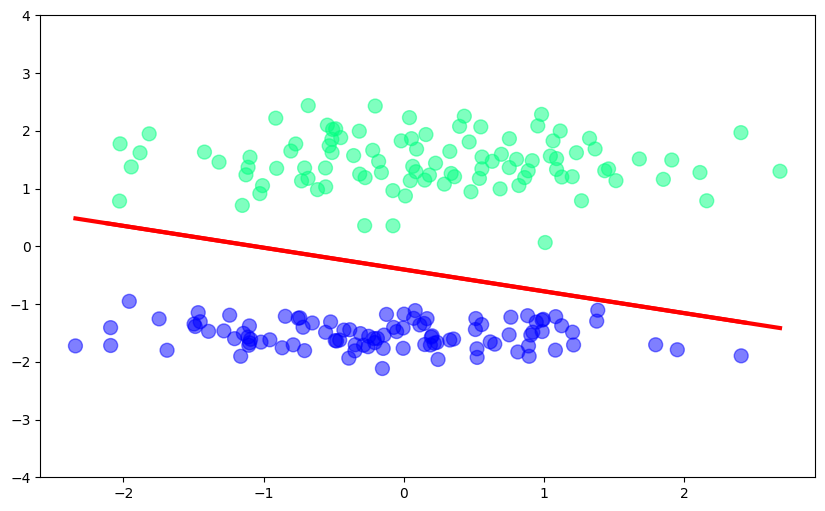

In [10]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100,alpha=0.5)
plt.ylim(-4,4)
plt.show()

what perceptron trick does , it randomly selects point and checks if it should be below the line or above the line and adjusts itself accordingly



In [11]:
def perceptron_trick(x,y):
  m = []
  b = []

  x = np.insert(x,0,1,axis=1)
  weights = np.ones(x.shape[1])
  lr = 0.1

  for i in range(100):
    j = np.random.randint(0,200)
    y_hat = step(np.dot(x[j],weights))
    weights = weights + lr*(y[j]-y_hat)*x[j]

    m.append(-(weights[1]/weights[2]))
    b.append(-(weights[0]/weights[2]))

  return m,b

In [12]:
m,b = perceptron_trick(x,y)

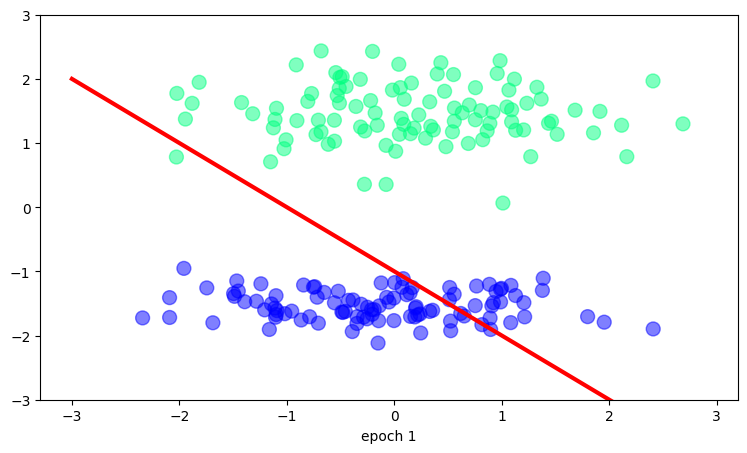

In [13]:
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

fig, ax = plt.subplots(figsize=(9,5))

x_i = np.arange(-3, 3, 0.1)
y_i = x_i*m[0] +b[0]
ax.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100,alpha=0.5)
line, = ax.plot(x_i, x_i*m[0] +b[0] , 'r-', linewidth=3)
plt.ylim(-3,3)
def update(i):
    label = 'epoch {0}'.format(i + 1)
    line.set_ydata(x_i*m[i] + b[i])
    ax.set_xlabel(label)
    # return line, ax

anim = FuncAnimation(fig, update, repeat=True, frames=len(m), interval=200)

In [14]:
from IPython.display import HTML
HTML(anim.to_jshtml())

using logistic regression instead of perceptron trick

In [15]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression()
lor.fit(x,y)

LogisticRegression()

In [16]:
m = -(lor.coef_[0][0] / lor.coef_[0][1])
b = -(lor.intercept_/lor.coef_[0][1])

print(m)
print(b)

-0.057135288281363175
[-0.1590841]


In [17]:
x_input = np.sort(x,axis=0)
y_input = m * x_input + b

much more clearer classification than perceptron trick

(-4.0, 4.0)

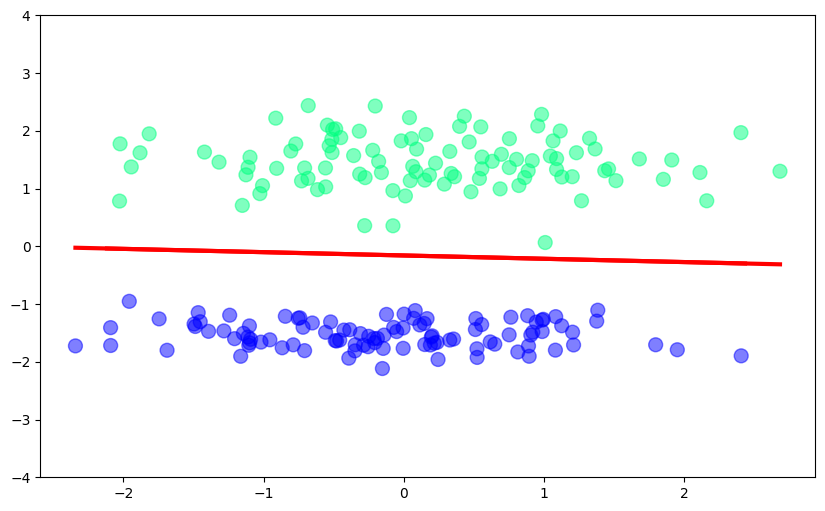

In [18]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100,alpha=0.5)
plt.ylim(-4,4)

if we use sigmoid function , in perceptron code

In [19]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

In [20]:
def perceptron_trick(x,y):
  m = []
  b = []

  x = np.insert(x,0,1,axis=1)
  weights = np.ones(x.shape[1])
  lr = 0.1

  for i in range(100):
    j = np.random.randint(0,200)
    y_hat = sigmoid(np.dot(x[j],weights))
    weights = weights + lr*(y[j]-y_hat)*x[j]

    m.append(-(weights[1]/weights[2]))
    b.append(-(weights[0]/weights[2]))

  return m,b

In [21]:
m,b = perceptron_trick(x,y)

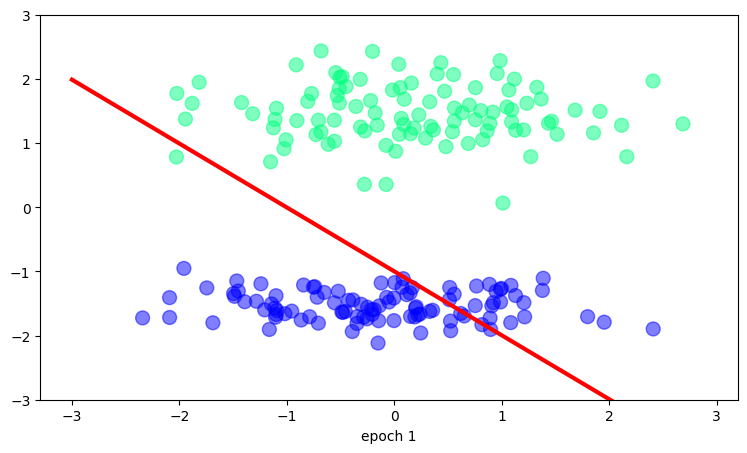

In [22]:
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

fig, ax = plt.subplots(figsize=(9,5))

x_i = np.arange(-3, 3, 0.1)
y_i = x_i*m[0] +b[0]
ax.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100,alpha=0.5)
line, = ax.plot(x_i, x_i*m[0] +b[0] , 'r-', linewidth=3)
plt.ylim(-3,3)
def update(i):
    label = 'epoch {0}'.format(i + 1)
    line.set_ydata(x_i*m[i] + b[i])
    ax.set_xlabel(label)
    # return line, ax

anim = FuncAnimation(fig, update, repeat=True, frames=len(m), interval=200)

better than previous one

In [23]:
from IPython.display import HTML
HTML(anim.to_jshtml())

but its still not as good as the logistic regression done in scikit learn

we also have to use a loss function and gradient descent

In [26]:
def gd(X,y):

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.5

    for i in range(5000):
        y_hat = sigmoid(np.dot(X,weights))
        weights = weights + lr*(np.dot((y-y_hat),X)/X.shape[0])

    return weights[1:],weights[0]

In [27]:
coef_,intercept_ = gd(x,y)
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

x_input1 = np.sort(x,axis=0)
y_input1 = m*x_input1 + b

nice

(-4.0, 4.0)

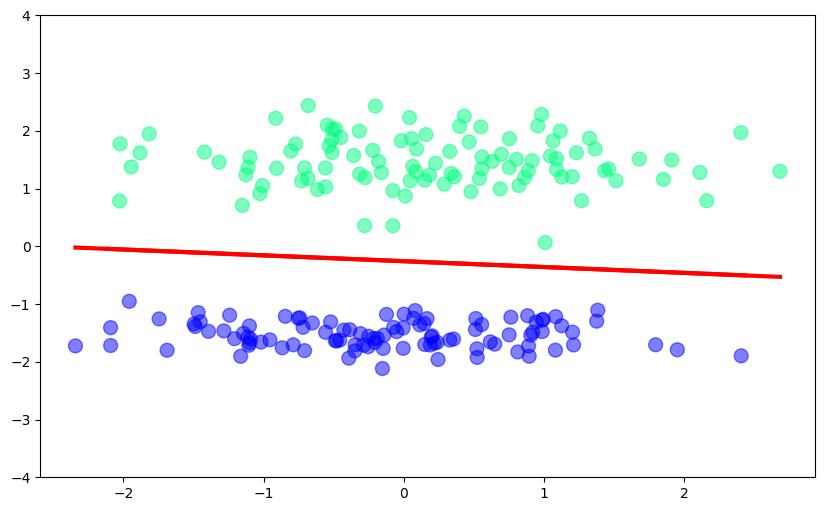

In [34]:
plt.figure(figsize=(10,6))
plt.plot(x_input1,y_input1,color='red',linewidth=3)
plt.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100,alpha=0.5)
plt.ylim(-4,4)